# Molecular Orbitals of Water

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/09-molecular-orbitals.ipynb)
:::


In [2]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = False

  Threads set to 4 by Python driver.

  Memory set to   1.863 GiB by Python driver.


Hartree–Fock and DFT build the wavefunction from **molecular orbitals** (MOs). *Psi4* gives us their energies and shapes. In this notebook we look at the **canonical** MOs (the ones the calculation produces directly) and then at **localized** MOs, which look like the bonds and lone pairs of a Lewis structure.

## What You Will Learn
- How to get orbital **energies**, **occupations** and **symmetry labels** from a wavefunction.
- How to compare orbital energies with **photoelectron spectroscopy** using Koopmans' theorem.
- How to draw orbitals from **cube files** in the notebook.
- How to **localize** the orbitals (Boys and Pipek–Mezey) and why the canonical and localized pictures describe the same molecule.

In [3]:
# send Psi4's text output to a file (False = overwrite it, don't append)
psi4.set_output_file("output/09-molecular-orbitalsO2.out", False);
# folder for the orbital cube files
cube_dir = output_dir / "mo_cubes"
cube_dir.mkdir(exist_ok=True)                 # create it if it does not exist yet
h2eV = psi4.constants.hartree2ev              # hartree → eV

## 1. The Calculation

```{note} Psi4 settings in this cell
:class: dropdown
`hf/cc-pvdz`
: Hartree–Fock orbitals have a clear meaning through **Koopmans' theorem**: minus the energy of an occupied orbital approximates the energy needed to remove an electron from it. *Alternatives:* DFT orbitals (`b3lyp`) have very similar shapes, but their energies are systematically too high (too small ionization energies) and should not be used with Koopmans' theorem. `hf/6-31g*` gives almost identical pictures.

`scf_type: "pk"`
: Exact integrals, so the orbital energies can be compared with other programs.
```

In [4]:
# water at its experimental geometry
water = psi4.geometry("""
0 1
O
O 1 0.9578
""")
psi4.set_options({"basis": "cc-pvdz", "scf_type": "pk"})   # pk = exact integrals
# HF energy; return_wfn=True keeps the wavefunction (orbitals and their energies)
E, wfn = psi4.energy("hf", molecule=water, return_wfn=True)


## 2. Orbital Energies and Symmetry Labels

Because water has $C_{2v}$ symmetry, *Psi4* stores the orbitals by **irreducible representation** ($a_1$, $a_2$, $b_1$, $b_2$). We collect them, sort by energy and number them within each symmetry, giving the standard labels $1a_1$, $2a_1$, $1b_2$, …

In [5]:
char_table = water.point_group().char_table()   # character table of water's point group (C2v), for the symmetry labels
ndocc = wfn.doccpi()                 # doubly occupied orbitals in each irrep

# collect every orbital: a label such as '2a1' (2nd orbital of a1 symmetry),
# its energy, and whether it is occupied
orbitals = []
for h in range(wfn.nirrep()):                 # loop over the symmetry types (irreps)
    irrep = char_table.gamma(h).symbol().lower()   # e.g. 'a1', 'b2'
    for i, eps in enumerate(wfn.epsilon_a().nph[h]):   # orbital energies within this irrep
        orbitals.append({"label": f"{i + 1}{irrep}", "energy (hartree)": eps,
                         "occupied": i < ndocc[h]})

mo_table = pd.DataFrame(orbitals).sort_values("energy (hartree)").reset_index(drop=True)   # all orbitals, sorted by energy
mo_table["energy (eV)"] = mo_table["energy (hartree)"] * h2eV   # hartree → eV
mo_table.head(8).round(3)                     # show the 8 lowest orbitals

,label,energy (hartree),occupied,energy (eV)
0,1ag,-20.691,True,-563.032
1,1b1u,-20.687,True,-562.934
2,2ag,-1.945,True,-52.930
3,2b1u,-1.009,True,-27.450
4,1b2u,-0.891,True,-24.246
5,1b3u,-0.806,True,-21.928
6,3ag,-0.803,True,-21.844
7,1b3g,-0.329,True,-8.945


Water has 10 electrons in 5 doubly occupied orbitals: $1a_1$ (the O 1s core), $2a_1$, $1b_2$, $3a_1$ and $1b_1$ (the HOMO). The lowest empty orbital (LUMO) is $4a_1$.

### An orbital energy diagram

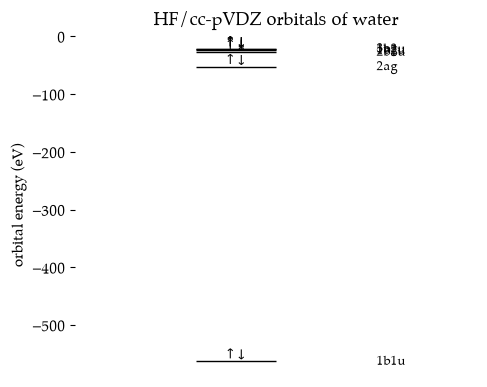

In [6]:
show = mo_table.iloc[1:7]          # skip the very deep 1s core orbital so the valence levels are visible

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
# each level is a short line with its label; ↑↓ marks an occupied orbital
for _, row in show.iterrows():
    ax.hlines(row["energy (eV)"], 0.3, 0.5, color="black", linewidth=1.0)
    ax.text(0.75, row["energy (eV)"], row["label"], va="center", fontsize=9)
    if row["occupied"]:
        ax.text(0.4, row["energy (eV)"], "↑↓", ha="center", va="bottom", fontsize=9, fontfamily="DejaVu Sans")
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.set_ylabel("orbital energy (eV)")
ax.set_title("HF/cc-pVDZ orbitals of water")
plt.show()

In [7]:
psi4.set_options({"cubeprop_tasks": ["orbitals"],   # write orbitals to cube files
                  "cubeprop_orbitals": [3, 4, 5, 6, 7, 8, 9,10],   # which orbitals, numbered from 1 in order of energy
                  "cubeprop_filepath": str(cube_dir)})   # where to write them
psi4.cubeprop(wfn)                            # write the cube files
psi4.molden(wfn, str(output_dir / "water.molden"))   # also save the orbitals in Molden format for other viewers
# list the orbital cube files
print(sorted(p.name for p in cube_dir.glob("Psi_a_*.cube")))

['Psi_a_10_3-B1u.cube', 'Psi_a_3_2-Ag.cube', 'Psi_a_4_2-B1u.cube', 'Psi_a_5_1-B2u.cube', 'Psi_a_5_1-B3u.cube', 'Psi_a_6_1-B2u.cube', 'Psi_a_6_1-B3u.cube', 'Psi_a_7_3-Ag.cube', 'Psi_a_8_1-B2g.cube', 'Psi_a_8_1-B3g.cube', 'Psi_a_9_1-B2g.cube', 'Psi_a_9_1-B3g.cube']


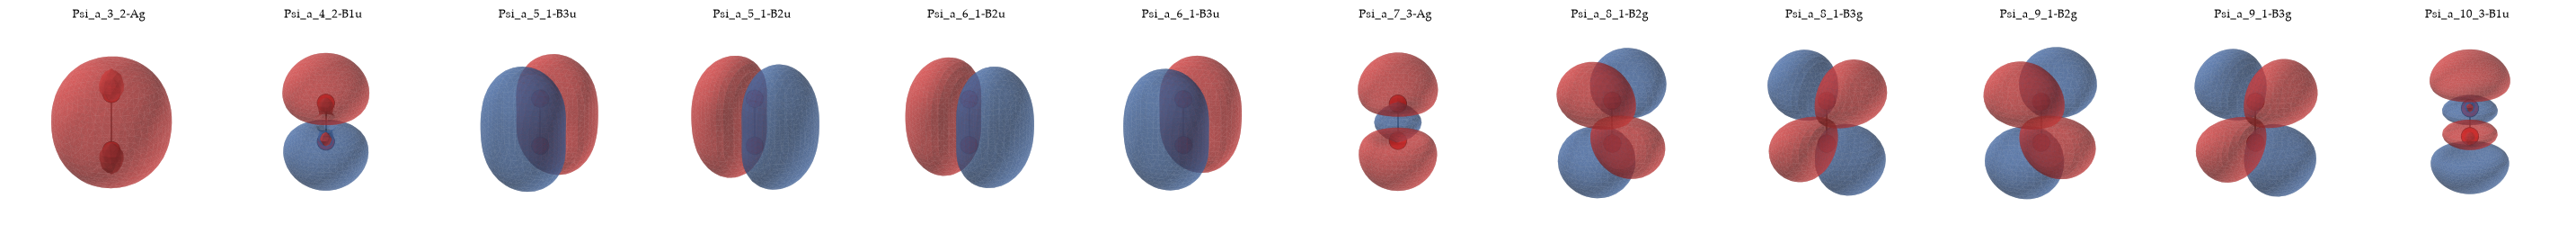

In [8]:
# get names of MO files in cube_dir. File names arive as unsorted list.
#  sort that list accorinding to the number * in "Psi_a_*.cube"
#  The lambda function splits out * as an integer so that 10 is sorted after 9.
mo_cubes = sorted(cube_dir.glob("Psi_a_*.cube"), 
                  key=lambda p: int(p.name.split("_")[2])) 

# use the helper function do display the cube files for each orbital 
#  in the sorted list, mo_cubes.
ph.show_orbitals(mo_cubes, 
                 titles=[p.stem for p in mo_cubes], 
                 mol=water, 
                 interactive=False, 
                 transparency=0.4)

The canonical orbitals are spread over the whole molecule and each has the symmetry of the molecule:

- $2a_1$: mostly O 2s, bonding to both H.
- $1b_2$: O 2p in the molecular plane, bonding to both H. It is the main O–H bonding orbital.
- $3a_1$: O 2p along the $C_2$ axis mixed with 2s; partly bonding, partly an **in-plane lone pair**.
- $1b_1$ (HOMO): a pure O 2p orbital perpendicular to the plane. It is an **out-of-plane lone pair** with no H character at all.
- $4a_1$ (LUMO): antibonding between O and H.

## 5. Localized Orbitals: Bonds and Lone Pairs

Any set of occupied orbitals can be mixed (rotated) among themselves without changing the total wavefunction, the electron density or the energy. **Localization** chooses the mixture that makes each orbital as compact as possible.

```{note} Psi4 settings: localization
:class: dropdown
`psi4.core.Localizer.build("BOYS", basis, C_occ)`
: **Boys** localization makes the orbital centres as far apart as possible. It is the classic method and tends to give the familiar "rabbit-ear" lone pairs.

`"PIPEK_MEZEY"`
: Maximizes the charge each orbital puts on as few atoms as possible. It keeps $\sigma$ and $\pi$ separation in planar molecules and can give a different description of lone pairs.

Other options
: Intrinsic bond orbitals (IBOs) are popular in teaching but are not part of standard *Psi4*. **Natural bond orbitals** (NBO) need the separate NBO program.

`wfn.Ca_subset("AO", "OCC")`
: The occupied orbital coefficients in the atomic-orbital basis, without symmetry blocking. Localized orbitals break the symmetry, so we must work without it.
```

In [9]:
C_occ = wfn.Ca_subset("AO", "OCC")            # coefficients of the occupied orbitals (one column per orbital)
cube_props = psi4.core.CubeProperties(wfn)    # tool that writes cube files for this wavefunction

localized = {}                                # localized orbitals from each method
# localize the occupied orbitals two ways: Boys pushes the orbital centres as far apart
# as possible; Pipek-Mezey puts each orbital's charge on as few atoms as possible
for method in ["BOYS", "PIPEK_MEZEY"]:
    loc = psi4.core.Localizer.build(method, wfn.basisset(), C_occ)
    loc.localize()                            # do the localization
    localized[method] = loc.L                 # store the localized orbital coefficients
    labels = [f"{method}{i + 1}" for i in range(loc.L.cols())]   # file labels: BOYS1, BOYS2, ...
    cube_props.compute_orbitals(loc.L, list(range(loc.L.cols())), labels, "LMO")   # write a cube file for each localized orbital

# list the localized-orbital cube files
print(sorted(p.name for p in cube_dir.glob("LMO_*.cube")))

['LMO_1_BOYS1.cube', 'LMO_1_PIPEK_MEZEY1.cube', 'LMO_2_BOYS2.cube', 'LMO_2_PIPEK_MEZEY2.cube', 'LMO_3_BOYS3.cube', 'LMO_3_PIPEK_MEZEY3.cube', 'LMO_4_BOYS4.cube', 'LMO_4_PIPEK_MEZEY4.cube', 'LMO_5_BOYS5.cube', 'LMO_5_PIPEK_MEZEY5.cube', 'LMO_6_BOYS6.cube', 'LMO_6_PIPEK_MEZEY6.cube', 'LMO_7_BOYS7.cube', 'LMO_7_PIPEK_MEZEY7.cube', 'LMO_8_BOYS8.cube', 'LMO_8_PIPEK_MEZEY8.cube']


In [10]:
F_ao = wfn.Fa_subset("AO").np               # Fock matrix in the AO basis (matches L's rows)

L = localized["BOYS"].np                      # Boys localized orbital coefficients
F_lmo = L.T @ F_ao @ L                      # Fock matrix in the LMO basis

# the diagonal elements are the 'energies' of the localized orbitals
# (an average over the canonical orbitals they are made from)
lmo_table = pd.DataFrame({"energy (hartree)": np.diag(F_lmo)},
                         index=[f"Boys LMO {i+1}" for i in range(L.shape[1])])
lmo_table["energy (eV)"] = lmo_table["energy (hartree)"] * h2eV   # hartree → eV
lmo_table.round(3)

,energy (hartree),energy (eV)
Boys LMO 1,-20.526,-558.536
Boys LMO 2,-20.526,-558.536
Boys LMO 3,-0.864,-23.502
Boys LMO 4,-0.864,-23.502
Boys LMO 5,-0.864,-23.502
Boys LMO 6,-1.327,-36.114
Boys LMO 7,-1.327,-36.114
Boys LMO 8,-0.864,-23.502


The same density, two descriptions: we check that the density built from the localized orbitals equals the canonical density.

In [11]:
# localizing only mixes the occupied orbitals among themselves, so the density
# matrix C Cᵀ should not change: the differences should be near zero
C = C_occ.np
for method, L in localized.items():
    diff = np.abs(C @ C.T - L.np @ L.np.T).max()
    print(f"{method:12s} largest difference in the density matrix: {diff:.1e}")

BOYS         largest difference in the density matrix: 1.3e-15
PIPEK_MEZEY  largest difference in the density matrix: 8.9e-16


### Boys localized orbitals

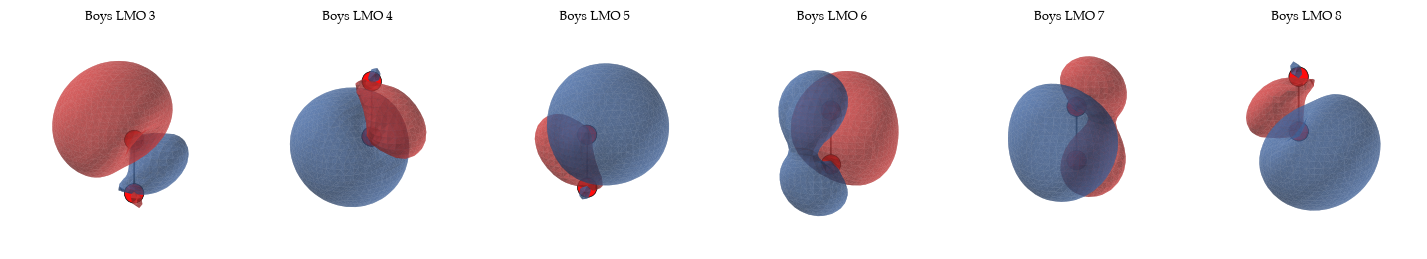

In [12]:
lmos = range(3, 9)          # orbital 1 is the O 1s core
# draw the four valence Boys orbitals: two O-H bonds and two lone pairs
ph.show_orbitals([cube_dir / f"LMO_{i}_BOYS{i}.cube" for i in lmos],
                 titles=[f"Boys LMO {i}" for i in lmos], mol=water, interactive=False, transparency=0.4)

Boys localization gives two equivalent **O–H bonds** and two equivalent **lone pairs** pointing above and below the molecular plane: the $sp^3$-like "rabbit ears" of the textbook picture.

### Pipek–Mezey localized orbitals

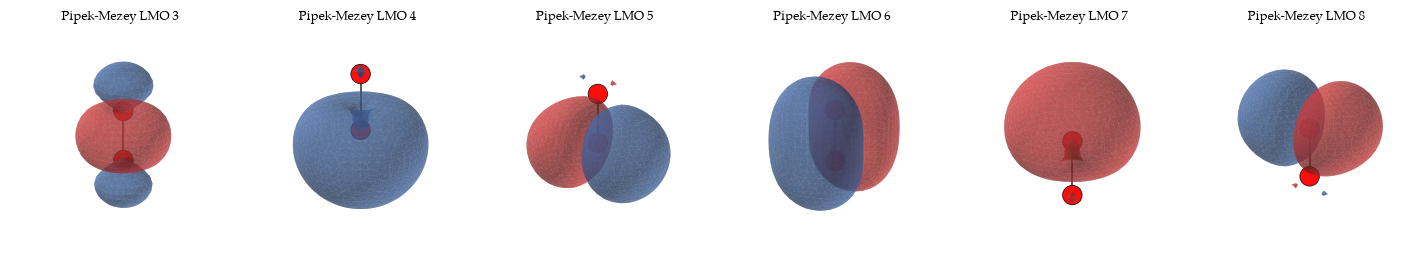

In [13]:
# the same for the Pipek-Mezey orbitals
ph.show_orbitals([cube_dir / f"LMO_{i}_PIPEK_MEZEY{i}.cube" for i in lmos],
                 titles=[f"Pipek-Mezey LMO {i}" for i in lmos], mol=water, interactive=False, transparency=0.4)

Pipek–Mezey gives the same two O–H bonds, but the lone pairs are different: one **$\sigma$-type** lone pair in the molecular plane (pointing away from the hydrogens, $sp$-like) and one **$\pi$-type** lone pair, a pure $p$ orbital perpendicular to the plane.

We can confirm this with numbers instead of pictures. The **centroid** of an orbital is the average position of its electron, $\langle \mathbf{r} \rangle$, calculated from the dipole integrals. In *Psi4*'s orientation, water lies in the $yz$ plane, so an orbital centred off the plane has a non-zero $x$ value.

In [14]:
mints = psi4.core.MintsHelper(wfn.basisset())   # calculates integrals over the basis functions
dipole_ints = [m.np for m in mints.ao_dipole()]          # x, y, z integrals in the AO basis

# centroid (average position) of each localized orbital = <φ|r|φ>;
# the dipole integrals include the electron's −1 charge, hence the minus sign
for method, L in localized.items():
    L = L.np
    rows = []
    for i in range(L.shape[1]):
        centroid = [-(L[:, i] @ d @ L[:, i]) * psi4.constants.bohr2angstroms for d in dipole_ints]
        rows.append(np.round(centroid, 3))
    print(method)
    print(pd.DataFrame(rows, columns=["x (Å)", "y (Å)", "z (Å)"], index=[f"LMO {i+1}" for i in range(L.shape[1])]))
    print()

BOYS
       x (Å)  y (Å)  z (Å)
LMO 1  -0.00  0.000  0.479
LMO 2  -0.00  0.000 -0.479
LMO 3  -0.00 -0.303  0.639
LMO 4  -0.00 -0.303 -0.639
LMO 5  -0.00  0.303  0.639
LMO 6  -0.21  0.000 -0.000
LMO 7   0.21  0.000  0.000
LMO 8  -0.00  0.303 -0.639

PIPEK_MEZEY
       x (Å)  y (Å)  z (Å)
LMO 1   -0.0   -0.0  0.481
LMO 2   -0.0   -0.0 -0.481
LMO 3   -0.0   -0.0  0.000
LMO 4   -0.0   -0.0 -0.763
LMO 5   -0.0   -0.0 -0.499
LMO 6   -0.0   -0.0  0.000
LMO 7   -0.0   -0.0  0.763
LMO 8   -0.0   -0.0  0.499



In the Boys set, two orbitals sit at $x = \pm 0.26$ Å: the rabbit ears above and below the plane. In the Pipek–Mezey set every centroid has $x = 0$; the $\pi$ lone pair is centred on the oxygen itself because its two lobes cancel.

```{important} Which picture is "right"?
Both. The canonical orbitals, the Boys orbitals and the Pipek–Mezey orbitals are different ways of dividing up **the same** wavefunction; the density matrix check above shows they are identical to rounding error ($10^{-16}$). They differ in what they make easy to see:

- The **canonical** orbitals have definite energies, so they explain the photoelectron spectrum with its **two different** lone-pair ionizations.
- **Localized** orbitals look like a Lewis structure and help explain the direction of bonds and hydrogen bonds.

Whether the textbook "rabbit-ear" lone pairs **should be taught** at all has been **debated** in the education literature: {cite:t}`Clauss2014` made an argument that the Boys **local orbital** scheme is a **disservice** to students; {cite:t}`Hiberty2015` **defended** the "rabbit-ears" (they wrote a textbook that made extensive use of that point of view and felt that the Clauss paper was all about them); Clauss was not backing down and wrote a **rebuttal** to the commentary of Hiberty et al. {cite:p}`Clauss2015`. I love a good fight. The **divergent** points of view really helped me to understand the nature of these **different** interpetations of the **same wavefunctions** and when they are useful.
```

## Summary
- Orbital **energies**, occupations and symmetry labels come directly from the **wavefunction**.
- Koopmans' theorem links HF orbital energies to the photoelectron **spectrum**.
- `psi4.cubeprop()` writes orbitals to **cube files**, which we can draw as fixed pictures or as rotatable **3D surfaces** (in that first code block, set `INTERACTIVE = True` to get interactive *py3Dmol* objects. The cube files that are included within the *py3Dmol* interactive objects are *huge*. This web book cannot be uploaded to the server with those objects included. You can view them by running this notebook on *Colab* with `INTERACTIVE = True`).
- **Localization** turns delocalized **canonical** MOs into bonds and lone pairs without changing the **wavefunction**.